# Models of different complexity and binned calibration: Figs. 4 and 5

Each model is trained once on its own training set and then kept fixed; the realised coverage of each calibrated predictor is computed from the known distribution of its scores. Runs in about 3 minutes on a workstation (most of it for the Friedman #1 models).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as st
from IPython.display import Image, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.special import ndtr
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

import reliable_conformal_prediction as rcp

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
import cp_plot as cpl  # noqa: E402
import cp_tools as ct  # noqa: E402

FIG = HERE / "figures"
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.simplefilter("ignore", rcp.InfeasibleRequestWarning)  # below the minimum size, the index is N_cal + 1 (trivial set)

C_NOM = C_MIN = 0.9
CONF = 0.95
N_SYN = 100
MS_SYN = {"std": rcp.get_index_standard(N_SYN, C_NOM), "new": rcp.get_index(N_SYN, C_MIN, CONF)}  # 91 and 96


def make_model(name, seed):
    """Regressors of increasing complexity (1-D input), hyperparameters fixed in advance."""
    if name.startswith("poly"):
        return make_pipeline(PolynomialFeatures(int(name[4:])), LinearRegression())
    if name == "forest":
        return RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=seed)
    if name == "gboost":
        return GradientBoostingRegressor(random_state=seed)
    if name == "mlp":
        return make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 64), max_iter=5000,
                                                            random_state=seed))
    raise ValueError(name)


def train_frozen(dgp, name, n_train, key):
    """Train a model on an independent training set and freeze it."""
    rng = np.random.default_rng(ct.seed_for(key))
    x, y = dgp.sample(rng, n_train)
    model = make_model(name, seed=int(rng.integers(2 ** 31)))
    model.fit(x[:, None], y)
    return ct.frozen(model)

## Fig. 4: one-dimensional problem (training sets of 30 and 300 points)

In [2]:
dgp = ct.calibrate_scale(ct.SyntheticDGP(noise=ct.Noise("gaussian")))  # t* = 1 for the perfect model
t_true = float(dgp.score_law().ppf(C_MIN))
rows = []
for n_train in (30, 300):
    for name in ("poly1", "poly4", "forest", "gboost", "mlp"):
        fhat = train_frozen(dgp, name, n_train, f"B6 train {name} n={n_train}")
        law = dgp.score_law(fhat=fhat, n_panels=1024)
        res = ct.run_mc(dgp, N_SYN, MS_SYN, 20_000, f"B6 {name} n={n_train}", fhat=fhat, law=law)
        for k, m in MS_SYN.items():
            cov, thr = res["cov"][k], res["thr"][k]
            frac, lo, hi = ct.frac_below(cov, C_MIN)
            rows.append(dict(task="1-D", n_train=n_train, model=name, procedure=k, mc_p_under=frac, ci99_low=lo,
                             ci99_high=hi, half_width_p05=np.quantile(thr, 0.05) / t_true,
                             half_width_p50=np.quantile(thr, 0.5) / t_true,
                             half_width_p95=np.quantile(thr, 0.95) / t_true))

## Fig. 4: Friedman #1 benchmark (five inputs, training set of 300 points)

In [3]:
def friedman1(x):
    return 10 * np.sin(np.pi * x[..., 0] * x[..., 1]) + 20 * (x[..., 2] - 0.5) ** 2 + 10 * x[..., 3] + 5 * x[..., 4]


class TabulatedScoreLaw:
    """Score law tabulated on a grid of thresholds (cdf by interpolation)."""

    def __init__(self, t, F):
        self.t, self.F = t, F

    def cdf(self, s):
        return np.interp(s, self.t, self.F, right=1.0)

    def ppf(self, u):
        return np.interp(u, self.F, self.t)


SIG_F = 1.0
rng = np.random.default_rng(ct.seed_for("B6 Friedman"))
rng.uniform(size=(100_000, 5))  # reference inputs of the original study, drawn first so that the random stream is the same
N_TRAIN_F = 300
x_tr = rng.uniform(size=(N_TRAIN_F, 5))
y_tr = friedman1(x_tr) + SIG_F * rng.standard_normal(N_TRAIN_F)
f_models = {"linear": LinearRegression(), "polynomial, degree 4": make_pipeline(PolynomialFeatures(4), LinearRegression()),
            "random forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=1),
            "gradient boosting": GradientBoostingRegressor(random_state=1),
            "MLP": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 64), max_iter=5000, random_state=1))}
t_grid = np.linspace(0, 15, 3001)
N_LAW, CHUNK_LAW = 4_000_000, 200_000  # inputs behind the score law of each model


def friedman_law(bias, weights=None):
    """Coverage of the band fhat +- t, averaged over the bias values b = f - fhat (with weights, if given)."""
    F = np.empty_like(t_grid)
    for i in range(0, t_grid.size, 100):
        tt = t_grid[i:i + 100, None]
        cov_t = ndtr((tt - bias) / SIG_F) - ndtr((-tt - bias) / SIG_F)
        F[i:i + 100] = cov_t.mean(axis=1) if weights is None else cov_t @ weights
    return TabulatedScoreLaw(t_grid, F)


def friedman_model_law(model):
    """Score law of a frozen model, through a fine histogram of its bias over N_LAW inputs."""
    rng_law = np.random.default_rng(ct.seed_for("B6 Friedman law"))
    bias = np.concatenate([friedman1(xx) - model.predict(xx)
                           for xx in (rng_law.uniform(size=(CHUNK_LAW, 5)) for _ in range(N_LAW // CHUNK_LAW))])
    counts, edges = np.histogram(bias, bins=20_000)
    return friedman_law(0.5 * (edges[1:] + edges[:-1]), counts / counts.sum())


t_true_f = float(friedman_law(np.zeros(1)).ppf(C_MIN))  # true threshold of the perfect model
R_F = 20_000
xs = rng.uniform(size=(R_F, N_SYN, 5))
ys = friedman1(xs) + SIG_F * rng.standard_normal((R_F, N_SYN))
for name, model in f_models.items():
    model.fit(x_tr, y_tr)
    law_f = friedman_model_law(model)
    pred = np.concatenate([model.predict(c) for c in np.array_split(xs.reshape(-1, 5), 40)])
    scores = np.abs(ys - pred.reshape(R_F, N_SYN))
    thr = ct.order_stats(scores, MS_SYN)
    for k, m in MS_SYN.items():
        frac, lo, hi = ct.frac_below(law_f.cdf(thr[k]), C_MIN)
        rows.append(dict(task="Friedman #1", n_train=N_TRAIN_F, model=name, procedure=k, mc_p_under=frac, ci99_low=lo,
                         ci99_high=hi, half_width_p05=np.quantile(thr[k], 0.05) / t_true_f,
                         half_width_p50=np.quantile(thr[k], 0.5) / t_true_f,
                         half_width_p95=np.quantile(thr[k], 0.95) / t_true_f))
T6 = pd.DataFrame(rows)

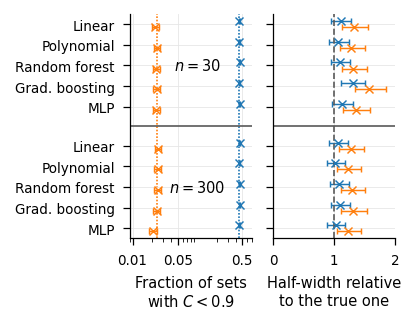

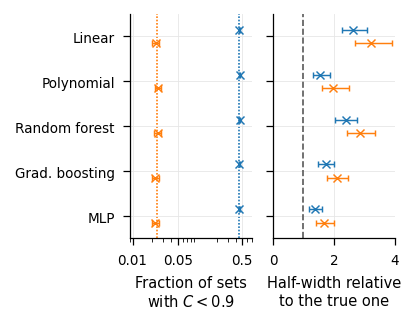

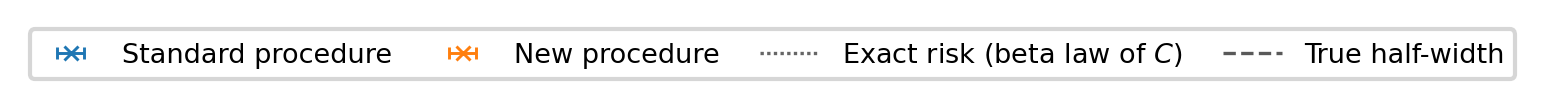

In [4]:
SHORT_F4 = {"poly1": "Linear", "linear": "Linear", "poly4": "Polynomial", "polynomial, degree 4": "Polynomial",
            "forest": "Random forest", "random forest": "Random forest", "gboost": "Grad. boosting",
            "gradient boosting": "Grad. boosting", "mlp": "MLP", "MLP": "MLP"}
EB4 = dict(fmt="x", ms=3.5, mew=0.7, lw=0.7, capsize=1.5, capthick=0.7)
SUB4 = (cpl.TEXT_WIDTH * 0.49, 2.05)
GAP4 = 0.9  # (a) one-dimensional problem and (b) Friedman #1, side by side in the paper
TICKS4 = [0.01, 0.05, 0.5]
with cpl.style():
    for task, stem, xmax in (("1-D", "fig_models_1d", 2.0), ("Friedman #1", "fig_models_f1", 4.0)):
        T = T6[T6.task == task].copy()
        T["row"] = T.groupby("procedure").cumcount()  # rows in the order of computation (n = 30 first for 1-D)
        yy = np.arange(T.row.max() + 1, dtype=float)
        if task == "1-D":
            yy[5:] += GAP4  # gap between the two training sizes
        fig, (a1, a2) = plt.subplots(1, 2, figsize=SUB4, sharey=True, layout="constrained")
        handles = []
        for k, off in (("std", -0.15), ("new", 0.15)):
            d = T[T.procedure == k].sort_values("row")
            p = d.mc_p_under.to_numpy()
            a1.errorbar(p, yy + off, xerr=[p - d.ci99_low, d.ci99_high - p], color=cpl.COL[k], **EB4)
            a1.axvline(1 - rcp.get_confidence(N_SYN, MS_SYN[k], C_MIN), color=cpl.COL[k], lw=0.8, ls=(0, (1, 1)), zorder=0)
            h = d.half_width_p50.to_numpy()
            handles.append(a2.errorbar(h, yy + off, xerr=[h - d.half_width_p05, d.half_width_p95 - h], color=cpl.COL[k],
                                       **EB4))
        if task == "1-D":  # two training sizes
            for a in (a1, a2):
                a.axhline(4.5 + GAP4 / 2, color="0.35", lw=0.8)
            for y0, n_tr in ((2, 30), (7 + GAP4, 300)):
                a1.text(0.1, y0, f"$n={n_tr}$", ha="center", va="center", color="k")
        a1.set_xscale("log")
        a1.set_xticks(TICKS4, [f"{t:g}" for t in TICKS4])
        a1.xaxis.set_minor_formatter(plt.NullFormatter())
        a1.set(xlim=(0.009, 0.7), xlabel="Fraction of sets\nwith $C<0.9$")
        a2.axvline(1, color=cpl.COL["oracle"], ls="--", lw=0.8)
        a2.set(xlim=(0, xmax), xlabel="Half-width relative\nto the true one")
        a1.set_yticks(yy, T[T.procedure == "std"].sort_values("row").model.map(SHORT_F4))
        a1.set_ylim(yy[-1] + 0.5, -0.5)  # first model at the top
        cpl.savefig(fig, stem, figdir=FIG)
        plt.show()
    # one legend for both subfigures
    handles += [Line2D([], [], color="0.4", ls=(0, (1, 1)), lw=0.8), Line2D([], [], color=cpl.COL["oracle"], ls="--", lw=0.8)]
    fig = plt.figure(figsize=(cpl.TEXT_WIDTH, 0.22))
    fig.legend(handles, [cpl.LABEL["std"], cpl.LABEL["new"], "Exact risk (beta law of $C$)", "True half-width"],
               loc="center", ncol=4, columnspacing=1.5)
    cpl.savefig(fig, "fig_models_legend", figdir=FIG)
    plt.close(fig)
display(Image(FIG / "fig_models_legend.png", width=810))  # the inline backend does not draw a figure without axes

## Fig. 5: input-dependent noise (two regimes), pooled calibration and calibration per regime

Per regime, the confidence is $(1-\alpha)^{1/2}$ (Šidák), so that the requirement holds in both regimes at once with confidence $1-\alpha$.

In [5]:
SIGMA = ct.two_regime(edge=0.7, ratio=3.0)
dgp = ct.calibrate_scale(ct.SyntheticDGP(noise=ct.Noise("gaussian"), sigma=SIGMA, breaks=(0.7,)))
law = dgp.score_law()
N7 = 200
ms7 = {"std": rcp.get_index_standard(N7, C_NOM), "new": rcp.get_index(N7, C_MIN, CONF)}
xg = np.linspace(0, 1, 1001)
# pooled calibration: quantiles over calibration sets of the coverage at each input
bands = {k: {p: dgp.cond_coverage(xg, ct.threshold_quantile(law, N7, m, p)) for p in (0.05, 0.5, 0.95)}
         for k, m in ms7.items()}

REGIMES = {"benign": (0.0, 0.7), "harsh": (0.7, 1.0)}
CONF_BIN = CONF ** (1 / 2)  # Šidák: (1 - alpha)^(1/2) per regime
M_BIN = {"std": lambda n: rcp.get_index_standard(n, C_NOM), "new": lambda n: rcp.get_index(n, C_MIN, CONF_BIN)}


def bin_mixture(m_of_n, N, p):
    """Bin size n ~ Binomial(N, p): (n, m) for the beta law (dummy valid values where infeasible), feasibility, P(n)."""
    n = np.arange(N + 1)
    m = np.array([m_of_n(k) if k > 0 else 1 for k in n])  # an empty bin has no threshold (m = n + 1)
    feasible = m <= n
    return np.where(feasible, n, 1), np.where(feasible, m, 1), feasible, st.binom.pmf(n, N, p)


def binned_coverage_quantiles(m_of_n, N, p, probs):
    """Quantiles over calibration sets of the coverage in a regime (an infeasible bin covers everything)."""
    n, m, feasible, pmf = bin_mixture(m_of_n, N, p)
    cg = np.linspace(0, 1, 20001)[:-1]
    F = (st.beta.cdf(cg[:, None], m, n + 1 - m) * feasible) @ pmf
    return {q: float(np.interp(q, F, cg)) if q <= F[-1] else 1.0 for q in probs}


q_reg = {k: {r: binned_coverage_quantiles(M_BIN[k], N7, b_ - a_, (0.05, 0.5, 0.95)) for r, (a_, b_) in REGIMES.items()}
         for k in M_BIN}
bands_bin = {k: {q: np.where(xg < 0.7, q_reg[k]["benign"][q], q_reg[k]["harsh"][q]) for q in (0.05, 0.5, 0.95)}
             for k in M_BIN}

# the calibration set shown in the top panels, and its thresholds
rng = np.random.default_rng(ct.seed_for("B7 one calibration set 3"))
x1, y1 = dgp.sample(rng, N7)
s1 = dgp.score(x1, y1)
t_pool = {k: np.sort(s1)[m - 1] for k, m in ms7.items()}
t_bin = {}
for k in M_BIN:
    t_r = {}
    for r, (a_, b_) in REGIMES.items():
        s_r = np.sort(s1[(x1 >= a_) & ((x1 < b_) if b_ < 1 else (x1 <= b_))])
        m = int(M_BIN[k](s_r.size))
        t_r[r] = s_r[m - 1] if m <= s_r.size else np.inf
    t_bin[k] = np.where(xg < 0.7, t_r["benign"], t_r["harsh"])

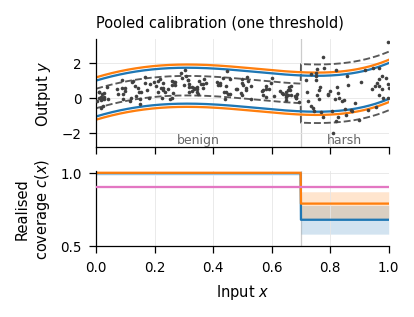

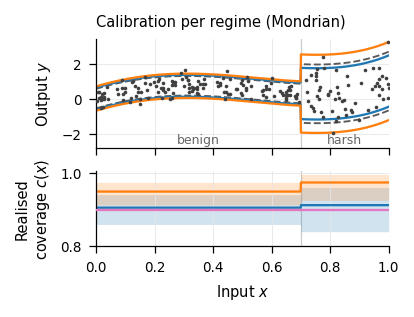

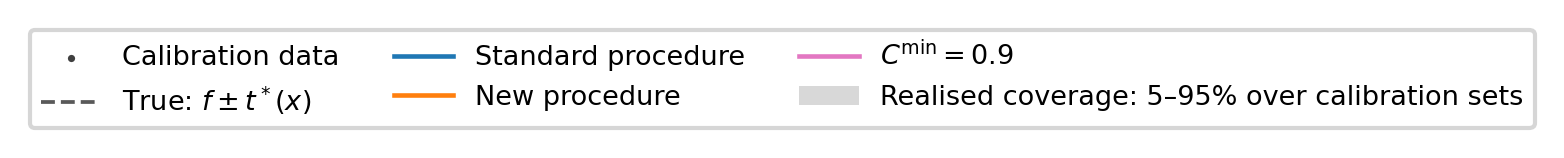

In [6]:
f_xg, t_x = dgp.f(xg), dgp.cond_oracle(xg, C_MIN)  # true function and true threshold at each input
SUBF9 = (cpl.TEXT_WIDTH * 0.49, 2.0)
YLIM_C = {"pooled": (0.5, 1.01), "bin": (np.floor(20 * min(bands_bin[k][0.05].min() for k in ms7)) / 20, 1.005)}
TITLE9 = {"pooled": "Pooled calibration (one threshold)", "bin": "Calibration per regime (Mondrian)"}
with cpl.style():
    for case, thr_x, bands_case in (("pooled", {k: np.full_like(xg, t_pool[k]) for k in ms7}, bands),
                                    ("bin", t_bin, bands_bin)):
        fig, (top, bot) = plt.subplots(2, 1, figsize=SUBF9, sharex=True, layout="constrained",
                                       gridspec_kw=dict(height_ratios=[1.45, 1]))
        top.scatter(x1, y1, s=3, color=cpl.COL["cal"], lw=0, zorder=3, label="Calibration data")
        for sign in (1, -1):
            top.plot(xg, f_xg + sign * t_x, color=cpl.COL["oracle"], ls="--", lw=0.9,
                     label="True: $f\\pm t^*(x)$" if sign == 1 else None)
            for k in ms7:
                top.plot(xg, f_xg + sign * thr_x[k], color=cpl.COL[k], lw=1.1,
                         label=cpl.LABEL[k] if sign == 1 else None)
        top.set(ylabel="Output $y$", ylim=(-2.8, 3.4), yticks=[-2, 0, 2])
        top.set_title(TITLE9[case])
        for x_, txt in ((0.35, "benign"), (0.85, "harsh")):
            top.text(x_, -2.72, txt, ha="center", va="bottom", color="0.4", fontsize=6)
        for k in ms7:
            bot.fill_between(xg, bands_case[k][0.05], bands_case[k][0.95], color=cpl.COL[k], alpha=0.2, lw=0)
            bot.plot(xg, bands_case[k][0.5], color=cpl.COL[k], lw=1.1)
        bot.axhline(C_MIN, color=cpl.COL["cmin"], lw=1.1, zorder=3)
        bot.set(xlabel="Input $x$", ylabel="Realised\ncoverage $c(x)$", ylim=YLIM_C[case], xlim=(0, 1))
        for a in (top, bot):
            a.axvline(0.7, color="0.8", lw=0.6, zorder=0)
        cpl.savefig(fig, "fig_bins_pooled" if case == "pooled" else "fig_bins_per_regime", figdir=FIG)
        plt.show()

    # one legend for both subfigures
    h, l = top.get_legend_handles_labels()
    h += [Line2D([], [], color=cpl.COL["cmin"], lw=1.1), Patch(fc="0.5", alpha=0.3, lw=0)]
    l += ["$C^{\\mathrm{min}}=0.9$", "Realised coverage: 5–95% over calibration sets"]
    fig = plt.figure(figsize=(cpl.TEXT_WIDTH, 0.32))
    fig.legend(h, l, loc="center", ncol=3)
    cpl.savefig(fig, "fig_bins_legend", figdir=FIG)
    plt.close(fig)
display(Image(FIG / "fig_bins_legend.png", width=810))  # the inline backend does not draw a figure without axes